In [1]:
from jax import grad, jvp, jit
import jax.numpy as jnp

In [2]:
class Tracer():
    
    def __init__(self, f):
        self._f = jit(f)
        self._grad = jit(grad(f))
        
        self.counter_f = 0
        self.counter_grad_f = 0
        
    def __call__(self, x):
        self.counter_f += 1
        return self._f(x)
    
    def grad(self, x):
        self.counter_grad_f += 1
        return self._grad(x)
    
    def reset(self):
        self.counter_f = 0
        self.counter_grad_f = 0
    
    def print_info(self):
        print(f"evals: {self.counter_f}\n"
              f"grad evals: {self.counter_grad_f}")

In [3]:
a = 20

F = Tracer(lambda x: a*x[0]**2 + x[1]**2)

#F(jnp.array([1.,1.]))

#F.print_info()

F.grad(jnp.array([1.,1.]))

F.print_info()

evals: 0
grad evals: 1


In [4]:
maxiter = 2000
tol = 1e-12
stepsize = 1/80  # insert alpha=1/L, alpha=2/L or alpha=1/(2L) here

x = jnp.array([1.,1.])
F.reset()

for i in range(maxiter):
    
    d = -F.grad(x)
    res_norm = jnp.linalg.norm(d)
    
    if res_norm <= tol:
        break
    elif i % 100 == 0:
        print(f"iteration {i}, ||grad(F)|| = {res_norm}")
        
    x = x + stepsize*d
    
F.print_info()

iteration 0, ||grad(F)|| = 40.04996871948242
iteration 100, ||grad(F)|| = 0.1590345799922943
iteration 200, ||grad(F)|| = 0.012645995244383812
iteration 300, ||grad(F)|| = 0.0010055756429210305
iteration 400, ||grad(F)|| = 7.996063504833728e-05
iteration 500, ||grad(F)|| = 6.358251994242892e-06
iteration 600, ||grad(F)|| = 5.055910037299327e-07
iteration 700, ||grad(F)|| = 4.02032398483243e-08
iteration 800, ||grad(F)|| = 3.19685211636056e-09
iteration 900, ||grad(F)|| = 2.542049626352849e-10
iteration 1000, ||grad(F)|| = 2.0213691831472147e-11
iteration 1100, ||grad(F)|| = 1.6073385027473575e-12
evals: 0
grad evals: 1120


In [5]:
def armijo(F, x, d, slope, c=0.5, tau=0.5, alpha0=1):
    """
    """

    alpha = alpha0
    Fx = F(x)
    cslope = c*slope
    
    while F(x + alpha*d) > Fx + alpha*cslope:
        
        alpha *= tau
        
    return alpha

In [6]:
x = jnp.array([1.,1.])
F.reset()

alpha = 1

for i in range(maxiter):
    d = -F.grad(x)
    
    res_norm = jnp.linalg.norm(d)
    
    if res_norm < tol:
        break
    elif i % 100 == 0:
        print(f"iteration {i}, ||grad(F)|| = {res_norm}")
     
    slope = -res_norm**2 
    alpha = armijo(F, x, d, slope, alpha0=1.2*alpha)
    
    x = x + alpha*d
    
F.print_info()

iteration 0, ||grad(F)|| = 40.04996871948242
iteration 100, ||grad(F)|| = 8.982308941085648e-07
iteration 200, ||grad(F)|| = 5.08160354073528e-12
evals: 494
grad evals: 217


In [7]:
# Heavy-ball armijo
x = jnp.array([1.,1.])
y = x.copy()

F.reset()

alpha = 1
beta = 0.1

for i in range(maxiter):
    
    d = -F.grad(x)
    
    res_norm = jnp.linalg.norm(d)
    
    if res_norm < tol:
        break
    elif i % 100 == 0:
        print(f"iteration {i}, ||grad(F)|| = {res_norm}")
     
    slope = F.grad(y)@d
    
    # check if d is a descent direction
    if slope < 0:
        alpha = armijo(F, y, d, slope, alpha0=1.2*alpha)
    else:
        alpha = 0
    
    x_old = x
    #print(f"F(y) = {F(y)}")
    #print(f'alpha = {alpha}')
    x = y + alpha*d
    #print(f"F(x) = {F(x)}")
    y = x + beta*(x - x_old)
    #print(f"F(y) = {F(y)}")
    #print()
    
F.print_info()

iteration 0, ||grad(F)|| = 40.04996871948242
iteration 100, ||grad(F)|| = 1.059015062310209e-06
evals: 451
grad evals: 395


In [8]:
# Heavy-ball constant
x = jnp.array([1.,1.])
y = x.copy()

F.reset()

alpha = 1
beta = 0.1

for i in range(maxiter):
    
    d = -F.grad(x)
    
    res_norm = jnp.linalg.norm(d)
    
    if res_norm < tol:
        break
    elif i % 100 == 0:
        print(f"iteration {i}, ||grad(F)|| = {res_norm}")

    alpha = 1/20
    
    x_old = x
    #print(f"F(y) = {F(y)}")
    #print(f'alpha = {alpha}')
    x = y + alpha*d
    #print(f"F(x) = {F(x)}")
    y = x + beta*(x - x_old)
    #print(f"F(y) = {F(y)}")
    #print()
    
F.print_info()

iteration 0, ||grad(F)|| = 40.04996871948242
iteration 100, ||grad(F)|| = 1.3033481081947684e-05
iteration 200, ||grad(F)|| = 8.35655294961768e-11
evals: 0
grad evals: 239


In [9]:
# Nesterov armijo
x = jnp.array([1.,1.])
y = x.copy()

F.reset()

alpha = 1
beta = 0.1

for i in range(maxiter):
    
    d = -F.grad(y)
    
    res_norm = jnp.linalg.norm(d)
    
    if res_norm < tol:
        break
    elif i % 100 == 0:
        print(f"iteration {i}, ||grad(F)|| = {res_norm}")
     
    slope = -jnp.linalg.norm(d)**2
        
    alpha = armijo(F, y, d, slope, alpha0=1.2*alpha)
    
    x_old = x
    #print(f"F(y) = {F(y)}")
    #print(f'alpha = {alpha}')
    x = y + alpha*d
    #print(f"F(x) = {F(x)}")
    y = x + beta*(x - x_old)
    #print(f"F(y) = {F(y)}")
    #print()
    
F.print_info()

iteration 0, ||grad(F)|| = 40.04996871948242
iteration 100, ||grad(F)|| = 1.0317922715330496e-05
iteration 200, ||grad(F)|| = 4.538438722057059e-11
evals: 522
grad evals: 230


In [10]:
# Nesterov constant
x = jnp.array([1.,1.])
y = x.copy()

F.reset()

alpha = 1
beta = 0.1
lmb = 0

for i in range(maxiter):
    
    d = -F.grad(y)
    
    res_norm = jnp.linalg.norm(d)
    
    if res_norm < tol:
        break
    elif i % 100 == 0:
        print(f"iteration {i}, ||grad(F)|| = {res_norm}")

    alpha = 1/80
    
    x_old = x
    #print(f"F(y) = {F(y)}")
    #print(f'alpha = {alpha}')
    x = y + alpha*d
    
    
    
    lmb_old = lmb
    lmb = 0.5*(1+jnp.sqrt(1+4*lmb**2))
    beta = (lmb_old-1)/lmb
    
    
    #print(f"F(x) = {F(x)}")
    y = x + beta*(x - x_old)
    #print(f"F(y) = {F(y)}")
    #print()
    
F.print_info()

iteration 0, ||grad(F)|| = 40.04996871948242
iteration 100, ||grad(F)|| = 0.005824624560773373
iteration 200, ||grad(F)|| = 0.00035392720019444823
iteration 300, ||grad(F)|| = 1.4900670066708699e-05
iteration 400, ||grad(F)|| = 4.733474270324223e-06
iteration 500, ||grad(F)|| = 2.447923179715872e-06
iteration 600, ||grad(F)|| = 8.319020139424538e-07
iteration 700, ||grad(F)|| = 2.4966627165667887e-07
iteration 800, ||grad(F)|| = 7.06525753457754e-08
iteration 900, ||grad(F)|| = 1.9298976638992826e-08
iteration 1000, ||grad(F)|| = 5.139807690568432e-09
iteration 1100, ||grad(F)|| = 1.340724975484875e-09
evals: 0
grad evals: 1172


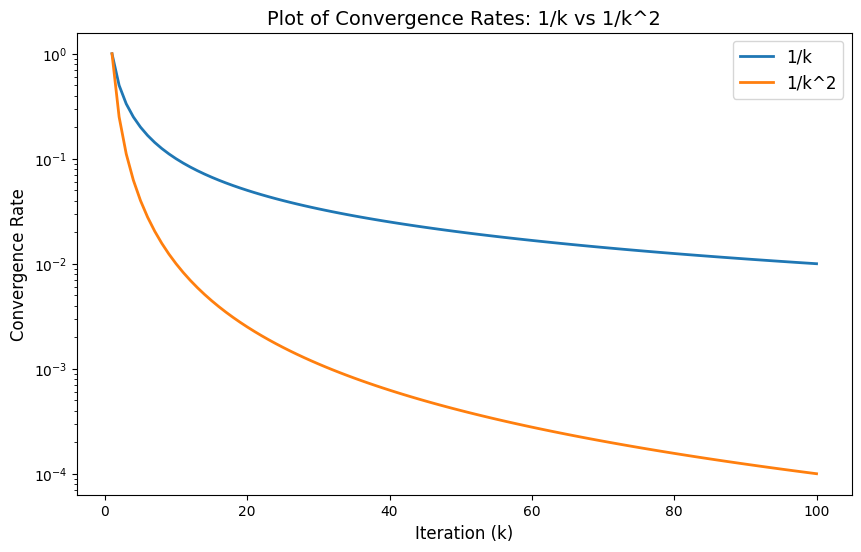

In [11]:
#log vs log-log plots
import numpy as np
import matplotlib.pyplot as plt

k = np.arange(1.0, 101.0)

y1 = 1 / k
y2 = 1 / k**2

plt.figure(figsize=(10, 6))

plt.plot(k, y1, label='1/k', linewidth=2)
plt.plot(k, y2, label='1/k^2', linewidth=2)

#axes to a logarithmic scale 
plt.yscale('log')
#plt.xscale('log')

plt.xlabel('Iteration (k)', fontsize=12)
plt.ylabel('Convergence Rate', fontsize=12)
plt.title('Plot of Convergence Rates: 1/k vs 1/k^2', fontsize=14)
plt.legend(fontsize=12)
#plt.grid(True, which="both", ls="--", alpha=0.7)

plt.show()